# Controle em cascata

**O diferencial:** usar uma medida intermediária para corrigir uma perturbação antes que ela se propague à saída principal.

Aqui há duas etapas: uma rápida, medida por `x`, e uma lenta, medida por `y`. Primeiro observo a identificação; depois comparo malha simples e cascata. Execute tudo e experimente os três ajustes do painel.

## O processo

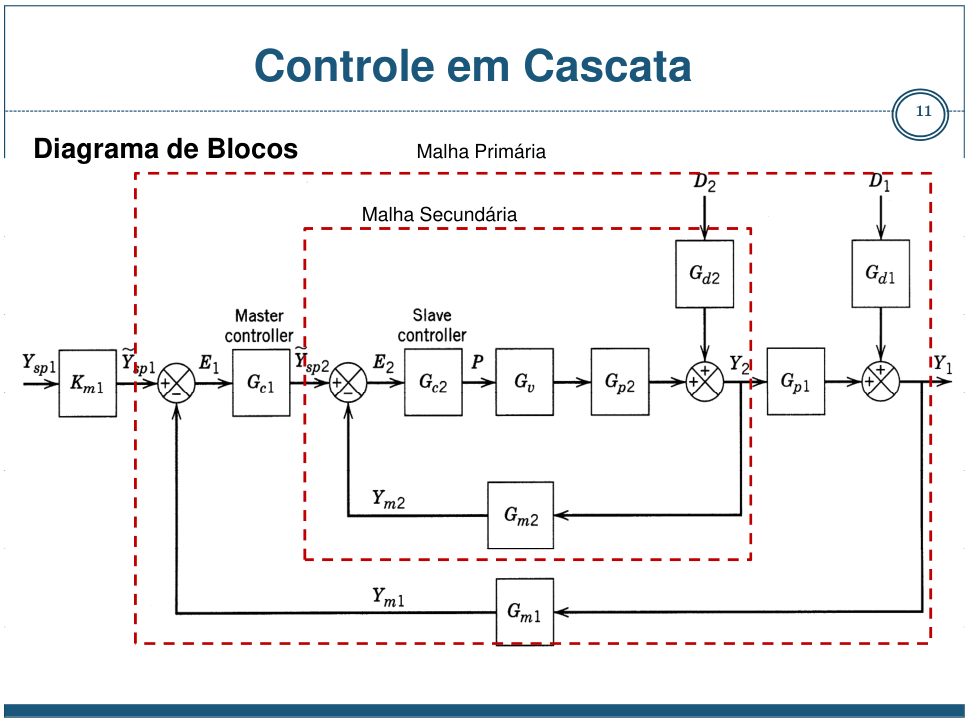

Neste esquema, a medida secundária volta ao PI interno; a principal volta ao externo. No ensaio abaixo, simplifico os nomes para `x` e `y`.

`comando → etapa rápida → x → etapa lenta → y`

Na malha simples, só `y` volta ao controlador. Na cascata, o PI externo pede um valor de `x`; o PI interno acompanha esse pedido. Os sinais são desvios normalizados, em unidades arbitrárias (u.a.), e o tempo está em segundos.

In [1]:
%pip -q install "control==0.10.2" "scipy>=1.13,<2" "numpy>=2,<3" "matplotlib>=3.8,<4" "ipywidgets>=8.1,<9"
import control as controle
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import ipywidgets as widgets
from IPython.display import display
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

## A planta

Usamos o caso numérico publicado: $G_2(s)=3e^{-3s}/(13{,}3s+1)$ e $G_1(s)=10(1-5s)e^{-5s}/[(30s+1)^3(10s+1)^2]$.

A etapa lenta é mantida completa na simulação. O PI usa uma aproximação mais simples; as diferenças e a origem dos modelos estão no [README](https://github.com/The-Celestino/toolbox-controle-classico/blob/main/estrategias/01_controle_cascata/README.md).

In [2]:
ganho_interno = 3.
constante_interna = 13.3
atraso_interno = 3.
s = controle.tf('s')
etapa_rapida_sem_atraso = ganho_interno / (constante_interna*s + 1)
etapa_lenta_sem_atraso = 10*(1 - 5*s) / ((30*s + 1)**3 * (10*s + 1)**2)

# Aproximo os atrasos só para fechar as funções de transferência.
def atraso_aproximado(segundos, ordem=3):
    return controle.tf(*controle.pade(segundos, ordem))

etapa_rapida = etapa_rapida_sem_atraso * atraso_aproximado(3)
etapa_lenta = etapa_lenta_sem_atraso * atraso_aproximado(5)

## Identificar com ruído

Aplico um degrau de 0,2 u.a. na etapa rápida. A medição simulada recebe ruído de desvio padrão 0,015 u.a. O atraso de 3 s é conhecido; vou estimar o ganho e a constante de tempo.

Ganho: 2.994; constante: 13.18 s


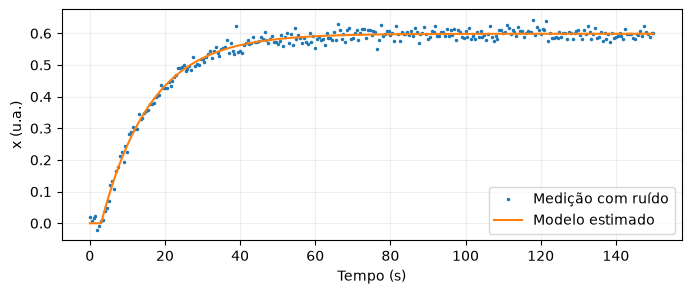

In [3]:
tempo_ensaio = np.linspace(0, 150, 301)
degrau_ensaio = .2
ruido_medicao = .015
def curva_degrau(tempo, ganho, constante):
    tempo_ativo = np.maximum(tempo - atraso_interno, 0)
    return ganho * degrau_ensaio * (1 - np.exp(-tempo_ativo/constante))

gerador = np.random.default_rng(20261009)
medicao_estimacao = curva_degrau(tempo_ensaio, 3., 13.3)
medicao_estimacao += gerador.normal(0, ruido_medicao, tempo_ensaio.size)
parametros_estimados, _ = curve_fit(curva_degrau, tempo_ensaio,
    medicao_estimacao, p0=[2., 10.], bounds=([.1, .1], [10., 100.]))
ganho_estimado, constante_estimada = parametros_estimados
modelo_estimado = ganho_estimado / (constante_estimada*s + 1)
print(f'Ganho: {ganho_estimado:.3f}; constante: {constante_estimada:.2f} s')
plt.figure(figsize=(8, 3))
plt.plot(tempo_ensaio, medicao_estimacao, '.', ms=3, label='Medição com ruído')
plt.plot(tempo_ensaio, curva_degrau(tempo_ensaio, *parametros_estimados), label='Modelo estimado')
plt.xlabel('Tempo (s)'); plt.ylabel('x (u.a.)'); plt.legend(); plt.grid(alpha=.2); plt.show()

## Validar sem ajustar de novo

Troco a entrada e a semente do ruído. A previsão usa os mesmos parâmetros: esta medição não participa do ajuste. O RMSE mede o erro em u.a.; comparo sua ordem de grandeza com a do ruído.

RMSE de validação: 0.0155 u.a. | ruído: 0.015 u.a.


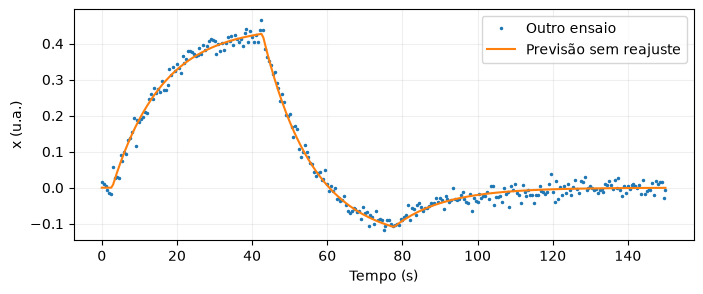

In [4]:
entrada_validacao = np.select(
    [tempo_ensaio < 40, tempo_ensaio < 75], [.15, -.05], default=0.)
entrada_atrasada = np.interp(tempo_ensaio - 3, tempo_ensaio,
    entrada_validacao, left=0)
saida_validacao = np.asarray(controle.forced_response(
    etapa_rapida_sem_atraso, tempo_ensaio, entrada_atrasada).outputs)
medicao_validacao = saida_validacao + np.random.default_rng(20261010).normal(
    0, ruido_medicao, tempo_ensaio.size)
previsao_validacao = np.asarray(controle.forced_response(
    modelo_estimado, tempo_ensaio, entrada_atrasada).outputs)
residuo_validacao = medicao_validacao - previsao_validacao
rmse_validacao = np.sqrt(np.mean(residuo_validacao**2))
print(f'RMSE de validação: {rmse_validacao:.4f} u.a. | ruído: {ruido_medicao:.3f} u.a.')
plt.figure(figsize=(8, 3))
plt.plot(tempo_ensaio, medicao_validacao, '.', ms=3, label='Outro ensaio')
plt.plot(tempo_ensaio, previsao_validacao, label='Previsão sem reajuste')
plt.xlabel('Tempo (s)'); plt.ylabel('x (u.a.)'); plt.legend(); plt.grid(alpha=.2); plt.show()

## Sintonizar por IMC

Para $K e^{-	heta s}/(	au s+1)$, uso $K_c=	au/[K(	au_c+	heta)]$ e $T_i=	au$.

Primeiro sintonizo o PI interno. Depois considero a malha interna fechada no projeto externo. Mantenho o tempo IMC externo em 120 s; o painel muda o interno. O caso é linear, sem limites de atuação.

In [5]:
def pi_imc(ganho, constante, atraso, tempo_imc):
    ganho_controlador = constante / (ganho*(tempo_imc + atraso))
    return ganho_controlador*(1 + 1/(constante*s))

tempo_imc_externo = 120.
def montar_malhas(tempo_imc_interno=10.):
    pi_interno = pi_imc(ganho_estimado, constante_estimada, 3., tempo_imc_interno)
    interna_fechada = controle.minreal(controle.feedback(pi_interno*etapa_rapida), verbose=False)
    # A etapa lenta tem primeiro momento de 115 s, antes do atraso.
    momento_interno = ganho_estimado/3. * (tempo_imc_interno + 3.)
    constante_externa = 115. + momento_interno - 3.
    pi_externo = pi_imc(10., constante_externa, 8., tempo_imc_externo)
    pi_simples = pi_imc(30., 115. + 13.3, 8., tempo_imc_externo)
    return pi_interno, interna_fechada, pi_externo, pi_simples

## Onde entra a perturbação?

Escolho uma mudança entre as etapas: ela aparece em `x` antes de alcançar `y`. Depois troco para uma mudança diretamente na saída principal. A medida interna não percebe imediatamente essa segunda mudança.

In [6]:
tempo = np.linspace(0, 1600, 1601)
instante_mudanca = 400.
def simular_comparacao(amplitude=.1, tempo_imc_interno=10., local='Entre as etapas'):
    _, interna, pi_externo, pi_simples = montar_malhas(tempo_imc_interno)
    sensibilidade_interna = controle.minreal(1 - interna, verbose=False)
    respostas = {}
    for nome, caminho, controlador in [('Malha simples', etapa_rapida, pi_simples),
                                       ('Cascata', interna, pi_externo)]:
        sensibilidade = controle.feedback(1, controlador*caminho*etapa_lenta)
        if local == 'Entre as etapas':
            canal_x = sensibilidade * (sensibilidade_interna if nome == 'Cascata' else 1)
            canal_y = etapa_lenta * canal_x
        else:
            canal_y = sensibilidade
            canal_x = -controlador*caminho*sensibilidade
        entrada = np.where(tempo >= instante_mudanca, amplitude, 0.)
        respostas[nome] = [np.asarray(controle.forced_response(
            controle.minreal(canal, verbose=False), tempo, entrada).outputs)
            for canal in [canal_y, canal_x]]
    return respostas

## Experimentar

1. Começo em **Entre as etapas** e comparo primeiro `x`, depois `y`.
2. Aumento o tempo IMC interno: a correção interna fica mais lenta.
3. Troco para **Na saída principal**. A vantagem da cascata continua igual?

A amplitude muda a intensidade do ensaio. O tempo IMC muda o controlador, não a planta.

In [7]:
def mostrar_comparacao(amplitude=.1, tempo_imc_interno=10., local='Entre as etapas'):
    respostas = simular_comparacao(amplitude, tempo_imc_interno, local)
    figura, eixos = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
    for nome, sinais in respostas.items():
        eixos[0].plot(tempo, sinais[0], label=nome)
        eixos[1].plot(tempo, sinais[1], label=nome)
        erro_acumulado = np.trapezoid(abs(sinais[0]), tempo)
        print(f'{nome}: erro acumulado em y = {erro_acumulado:.2f} u.a.·s')
    for eixo in eixos:
        eixo.axvline(instante_mudanca, color='gray', ls=':', lw=1)
        eixo.axhline(0, color='black', lw=.6); eixo.grid(alpha=.2)
    eixos[0].set_ylabel('Saída principal y (u.a.)'); eixos[0].legend()
    eixos[1].set_ylabel('Medida interna x (u.a.)'); eixos[1].set_xlabel('Tempo (s)')
    plt.tight_layout(); plt.show()

In [8]:
amplitude = widgets.FloatSlider(value=.1, min=.02, max=.2, step=.02,
    description='Amplitude', continuous_update=False)
tempo_interno = widgets.FloatSlider(value=10, min=10, max=60, step=5,
    description='IMC interno (s)', continuous_update=False, style={'description_width':'initial'})
local_mudanca = widgets.Dropdown(options=['Entre as etapas', 'Na saída principal'],
    description='Mudança', value='Entre as etapas')
painel = widgets.interactive_output(mostrar_comparacao,
    {'amplitude':amplitude, 'tempo_imc_interno':tempo_interno, 'local':local_mudanca})
display(widgets.VBox([local_mudanca, amplitude, tempo_interno]), painel)

Output()

A cascata acrescenta informação e uma malha de realimentação. Ela é especialmente útil quando a variável interna é rápida e mede a perturbação relevante. O gráfico não promete que duas malhas sempre serão melhores.

## Referências

Franklin, T. S.; Santos, T. L. M.; Araújo, J. M. (2020). **Critério de estabilidade simplificado para sistemas lineares em cascata com atraso variável: uma abordagem via preditor de Smith Filtrado**. CBA 2020. [Artigo](https://ojs.sba.org.br/index.php/cba/article/view/1258), eqs.20–21.

Esta toolbox usa os modelos do estudo de caso com PIs por IMC e atraso fixo; não reproduz o preditor nem a análise de atraso variável do artigo. [Teoria, bibliotecas e materiais de apoio](https://github.com/The-Celestino/toolbox-controle-classico/blob/main/estrategias/01_controle_cascata/README.md).

Imagem: recorte do diagrama de blocos, slide 11, de Bojorge, N. **Controle em Cascata**, UFF (2017). [Material institucional](https://www.professores.uff.br/ninoska/wp-content/uploads/sites/57/2017/11/Aula-25-Controle-Cascata2017_2sem17.pdf). É uma ilustração conceitual, não a figura da planta numérica do artigo.